# Métodos del mapa de investigación (versión sencilla)

Este notebook explica, con palabras sencillas, los métodos del mapa de investigación sobre monitoreo de puentes con teléfonos que van dentro de un carro (*drive-by*). Tiene los mismos métodos, en el mismo orden y con la misma numeración que la versión técnica: [research_map_methods.ipynb](research_map_methods.ipynb).

<a id="indice"></a>
## Índice

- [2 Modal identification](#modal-identification)
  - [2.2 Mode shapes](#mode-shapes)
    - [2.2.2 Signal decomposition](#mode-shapes-signal-decomposition)
      - [2.2.2.1 EMD + Hilbert transform](#emd-hilbert)
      - [2.2.2.2 Wavelet transform (SSWT)](#wavelet-sswt)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import Wavelet, ssq_cwt
from ssqueezepy.experimental import scale_to_freq
from PyEMD import EMD
from scipy.signal import hilbert

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

# Synthetic example (same as the technical notebook): a car crosses a 100 m bridge at 20 m/s
L = 100.0                               # bridge length, m
v = 20.0                                # car speed, m/s
f_mode = 1.3                            # bridge "note" (mode 2 frequency), Hz
fs = 100.0                              # sampling rate, Hz

t = np.arange(0, L / v, 1 / fs)         # time, s
pos = v * t                             # car position on the bridge, m
shape_true = np.sin(2 * np.pi * pos / L)  # how the bridge bends: up on one half, down on the other
x = np.abs(shape_true) * np.cos(2 * np.pi * f_mode * t) + 0.1 * rng.standard_normal(t.size)

# Wavelet maps: CWT (Wx) and synchrosqueezed SSWT (Tx), analytic Morlet wavelet
wavelet = Wavelet(("morlet", {"mu": 3}))
Tx, Wx, freqs_ssq, scales = ssq_cwt(x, wavelet, fs=fs, nv=32, padtype="zero")
freqs_cwt = scale_to_freq(scales, wavelet, N=2 ** 14, fs=fs)

---

<a id="modal-identification"></a>
## 2 Modal identification

---

<a id="mode-shapes"></a>
### 2.2 Mode shapes

<a id="mode-shapes-signal-decomposition"></a>
#### 2.2.2 Signal decomposition

<a id="emd-hilbert"></a>
##### 2.2.2.1 EMD + Hilbert transform

*Versión técnica: [research_map_methods.ipynb, sección 2.2.2.1](research_map_methods.ipynb#emd-hilbert)*

**Qué es**

- La EMD es una forma de separar una vibración en capas, de la más rápida a la más lenta.
- Analogía: es como pelar una cebolla. Primero sale la capa de afuera, la vibración más rápida; luego la siguiente, y así hasta llegar al centro, que es la tendencia lenta.
- Cada capa se llama IMF. Es una vibración sencilla, que sube y baja de forma pareja.
- La transformada de Hilbert mira cada capa y dice, en cada momento, qué tan fuerte vibra y qué tan rápido.
- Analogía: es como tener en cada capa un medidor de volumen y un velocímetro.

**Para qué sirve**

- Para vibraciones que cambian mientras se miden.
- En un puente: para encontrar la capa que viene del puente y ver qué tan fuerte vibra en cada punto mientras el carro pasa.
- Analogía: es como seguir con el oído solo la guitarra en una canción, y notar cuándo suena más fuerte y cuándo más suave.

**Cómo funciona**

1. Se marcan los picos altos y los picos bajos de la vibración.
2. Se dibuja una línea que une los picos altos y otra que une los bajos.
3. Se saca el punto medio entre las dos líneas y se le resta a la vibración. Se repite hasta que lo que queda sube y baja de forma pareja. Esa es la primera capa.
4. Se le quita esa capa a la vibración original y se repite todo con lo que sobra, para sacar la siguiente capa.
5. Cuando lo que queda ya no sube y baja, se termina.
6. A cada capa se le pasa Hilbert, que dice su fuerza y su velocidad en cada momento.

Analogía de los pasos 1 a 3: es como un camino con curvas entre dos bordes. Se marca la línea del centro del camino y se mide cuánto se aleja el carro de ella.

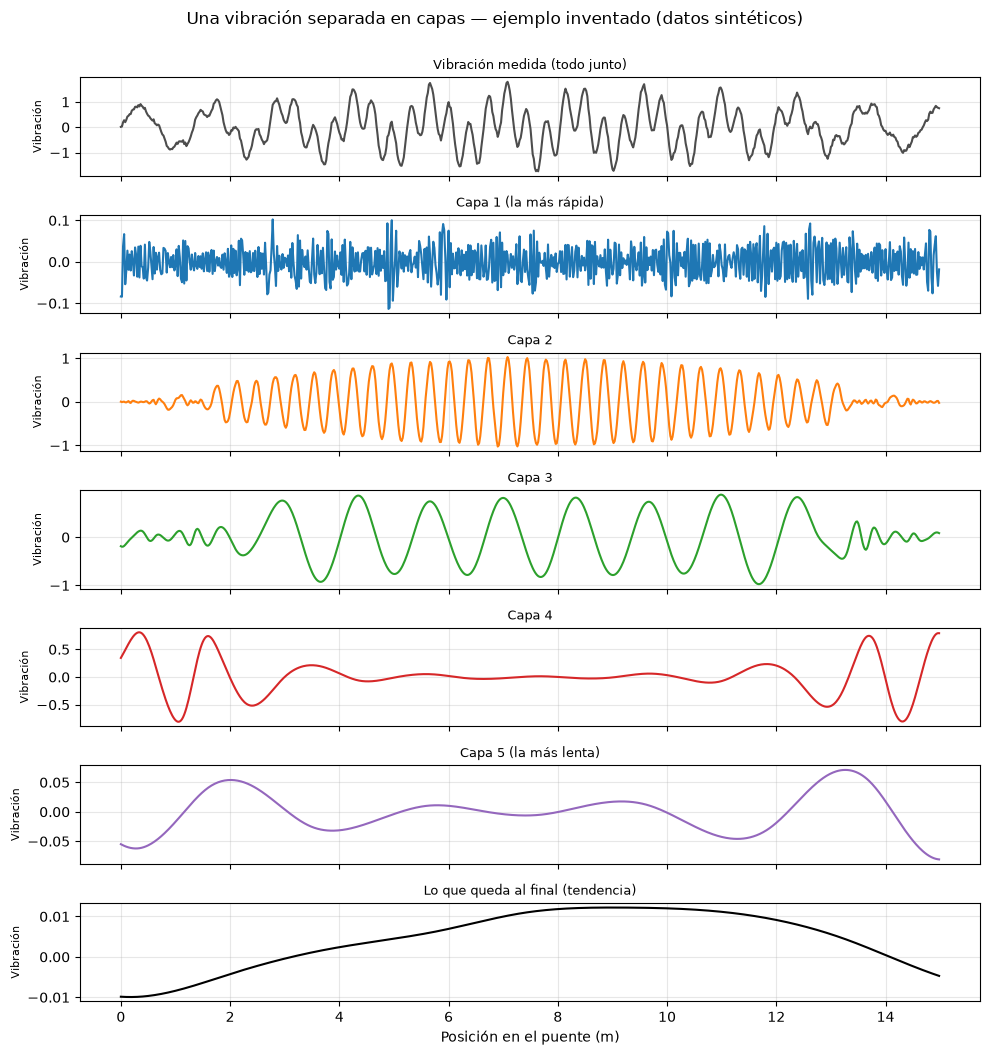

In [2]:
# Example: car crossing a 15 m bridge at 2 m/s (same as the technical notebook)
rng_emd = np.random.default_rng(SEED)   # own generator: keeps the other sections unchanged
L_b, v_b, f_b, fs_b = 15.0, 2.0, 5.65, 100.0   # length (m), speed (m/s), bridge note (Hz), samples per second
t_b = np.arange(0, L_b / v_b, 1 / fs_b)        # time, s
pos_b = v_b * t_b                              # car position on the bridge, m
shape_b = np.sin(np.pi * pos_b / L_b)          # how the bridge bends (mode 1)
x_b = (np.abs(shape_b) * np.cos(2 * np.pi * f_b * t_b)     # bridge vibration
       + 0.8 * np.sin(2 * np.pi * 1.5 * t_b)              # car vibration (made up, 1.5 Hz)
       + 0.05 * rng_emd.standard_normal(t_b.size))        # noise

emd_b = EMD()
emd_b.emd(x_b, t_b)
layers, rest = emd_b.get_imfs_and_residue()

fig, axes = plt.subplots(len(layers) + 2, 1, figsize=(10, 1.5 * (len(layers) + 2)), sharex=True)
axes[0].plot(pos_b, x_b, color="0.3")
axes[0].set_title("Vibración medida (todo junto)", fontsize=9)
for i, layer in enumerate(layers):
    axes[i + 1].plot(pos_b, layer, color=f"C{i}")
    label = "la más rápida" if i == 0 else ("la más lenta" if i == len(layers) - 1 else "")
    axes[i + 1].set_title(f"Capa {i + 1}" + (f" ({label})" if label else ""), fontsize=9)
axes[-1].plot(pos_b, rest, color="k")
axes[-1].set_title("Lo que queda al final (tendencia)", fontsize=9)
for ax in axes:
    ax.set_ylabel("Vibración", fontsize=8)
axes[-1].set_xlabel("Posición en el puente (m)")
fig.suptitle("Una vibración separada en capas — ejemplo inventado (datos sintéticos)", y=1.0)
fig.tight_layout()
plt.show()

**Figura 1.** Una vibración inventada separada en capas (ilustrativo): arriba está todo junto; debajo, las capas de la más rápida a la más lenta. La capa 1 es el ruido, la capa 2 es la vibración del puente y la capa 3 es la del carro. En las orillas las capas 3 y 4 se mezclan un poco: es el problema de las orillas que aparece en Desventajas.

**Cómo se usa para la forma modal**

- La forma modal es el dibujo de cómo se deforma el puente cuando vibra en una de sus notas.
- Se busca la capa que vibra a la "nota" del puente.
- Se mira qué tan fuerte vibra esa capa en cada punto del recorrido.
- Donde vibra fuerte, el puente se mueve mucho; donde casi no vibra, el puente casi no se mueve.
- Analogía: es como poner la mano en distintos puntos de una mesa que tiembla. Donde más tiembla, más se mueve la mesa.

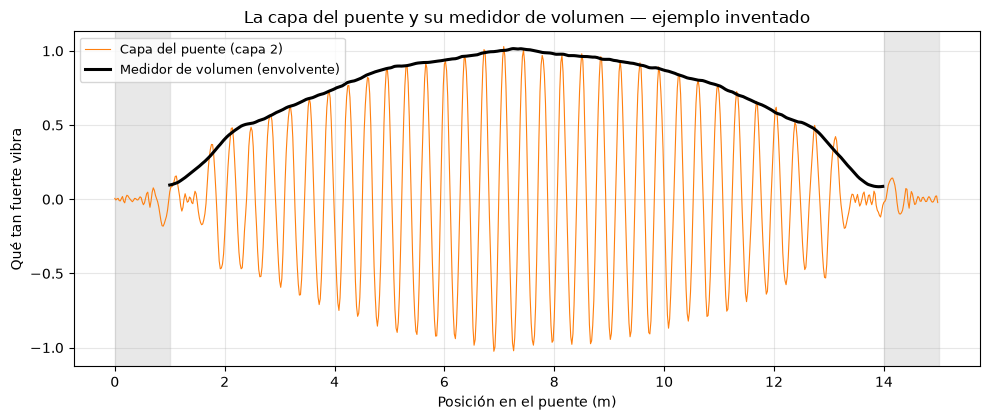

In [3]:
# Bridge layer and its "volume meter" (envelope) along the bridge
speeds = []
for layer in layers:
    phase = np.unwrap(np.angle(hilbert(layer)))
    speeds.append(np.median(np.gradient(phase) * fs_b / (2 * np.pi)))   # typical note of each layer, Hz
k_bridge = int(np.argmin(np.abs(np.array(speeds) - f_b)))           # layer closest to the bridge note
bridge_layer = layers[k_bridge]
volume = np.abs(hilbert(bridge_layer))                               # envelope from Hilbert
win = int(0.5 * fs_b)
volume_smooth = np.convolve(volume, np.ones(win) / win, mode="same") # smoothed (0.5 s moving average)
inner = slice(win, -win)                                             # ends are not reliable

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos_b, bridge_layer, color="C1", lw=0.8, label=f"Capa del puente (capa {k_bridge + 1})")
ax.plot(pos_b[inner], volume_smooth[inner], color="k", lw=2.2, label="Medidor de volumen (envolvente)")
for edge in [(0, pos_b[win]), (pos_b[-win], L_b)]:
    ax.axvspan(*edge, color="0.85", alpha=0.6)
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Qué tan fuerte vibra")
ax.set_title("La capa del puente y su medidor de volumen — ejemplo inventado")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

**Figura 2.** La capa del puente con su medidor de volumen (ilustrativo, datos sintéticos): vibra poco en las orillas y fuerte en el centro, que es justo la forma en que se mueve este puente. Las franjas grises son el inicio y el final, donde el resultado no es confiable y se recorta.

**Ventajas**

- Las capas salen de la propia vibración; no hay que escoger una onda de prueba.
- Sirve para vibraciones que cambian.
- Dice la fuerza y la velocidad en cada instante.

**Desventajas**

- A veces dos vibraciones distintas quedan mezcladas en la misma capa.
- Analogía: es como cuando en una foto dos personas quedan pegadas y parecen una sola.
- En el inicio y el final de la señal las líneas se deforman, así que esas partes no son confiables.
- El ruido la afecta bastante.
- Hay que saber qué "nota" del puente buscar.

**Artículos:** Malekjafarian y OBrien (2017).

**Entradas y salidas**

- **Entrada:** la vibración medida y, para el puente, la posición del carro y la nota que se busca.
- **Salida:** las capas de la vibración y, para cada una, su fuerza y su velocidad en cada momento.
- **Qué se obtiene o interpreta:** qué capa viene del puente y qué tan fuerte vibra en cada punto, que es la base para dibujar cómo se deforma el puente.

[↑ Volver al índice](#indice)

<a id="wavelet-sswt"></a>
##### 2.2.2.2 Wavelet transform (SSWT)

*Versión técnica: [research_map_methods.ipynb, sección 2.2.2.2](research_map_methods.ipynb#wavelet-sswt)*

**Qué es**

- Es una herramienta que escucha una vibración y dice qué "notas" tiene y en qué momento suena cada una.
- Una "nota" es una frecuencia: cuántas veces por segundo se mueve algo de ida y vuelta.
- Analogía: es como una partitura. Fourier te dice qué notas hay en la canción completa; la wavelet además te dice en qué compás suena cada nota.

**Para qué sirve**

- Para vibraciones cortas o que cambian mientras se miden, como la de un carro que cruza un puente en pocos segundos.
- Con ella se puede ver cómo cambia la fuerza de una vibración del puente a medida que el carro avanza.
- Analogía: es como escuchar a alguien que pasa hablando frente a tu ventana. Solo lo oyes unos segundos, y su voz sube y baja mientras se acerca y se aleja.

**Cómo funciona**

1. Se toma una "onda de prueba": una pequeña vibración que empieza, oscila y se apaga, como el sonido de una campana.
2. Esa onda se hace más larga o más corta para probar cada nota (frecuencia).
3. Se va deslizando sobre la señal. Donde la señal vibra igual que la onda de prueba, "coinciden" y da un valor grande; donde no, da casi cero. Analogía: es como pasar un imán por la arena; solo se pegan las limaduras de hierro.
4. Con todos esos valores se arma un mapa de colores: el tiempo en un eje, las notas en el otro y el color indica qué tan fuerte suena cada nota en cada momento.

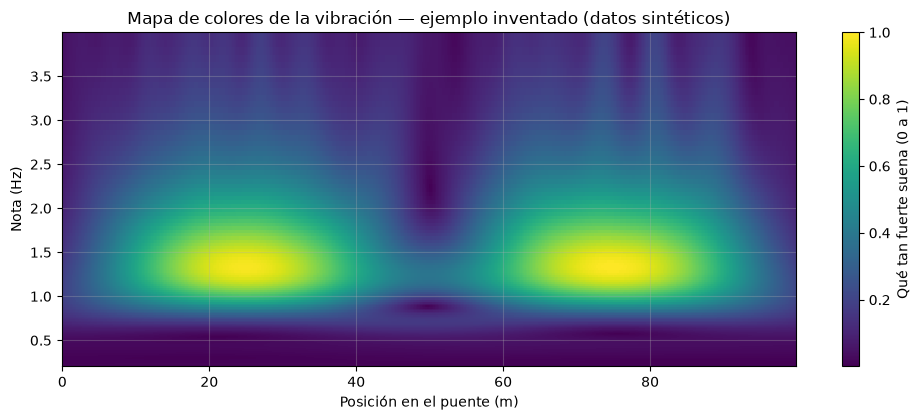

In [4]:
# Color map of the wavelet (CWT magnitude) versus car position
f_max = 4.0                                  # highest note shown, Hz
keep = freqs_cwt <= f_max
strength = np.abs(Wx[keep]) / np.abs(Wx).max()   # normalized: 1 = loudest

fig, ax = plt.subplots(figsize=(10, 4.3))
mesh = ax.pcolormesh(pos, freqs_cwt[keep], strength, shading="auto", cmap="viridis")
fig.colorbar(mesh, ax=ax, label="Qué tan fuerte suena (0 a 1)")
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Nota (Hz)")
ax.set_title("Mapa de colores de la vibración — ejemplo inventado (datos sintéticos)")
fig.tight_layout()
plt.show()

**Figura 3.** Mapa de colores de una vibración inventada (ilustrativo): la nota de 1.3 Hz suena fuerte al inicio del puente, se apaga en el centro (50 m) y vuelve a sonar al final.

**Cómo se usa para la forma modal**

- La forma modal es el dibujo de cómo se deforma el puente cuando vibra en una de sus notas.
- El GPS dice dónde estaba el carro en cada momento, así que el tiempo se convierte en posición sobre el puente.
- Se mira solo la "nota" del puente que interesa y se ve qué tan fuerte suena en cada punto. Donde suena fuerte, el puente se mueve mucho; donde casi no suena, el puente casi no se mueve.
- Analogía: es como una cuerda de guitarra que vibra. Algunos puntos se mueven mucho y otros casi nada; si pasas el dedo por encima, sientes dónde vibra más.
- Juntando muchos viajes, se obtiene el dibujo de cómo se deforma el puente al vibrar.
- Analogía: es como tomar muchas fotos movidas de lo mismo y superponerlas; la forma se ve cada vez más clara.

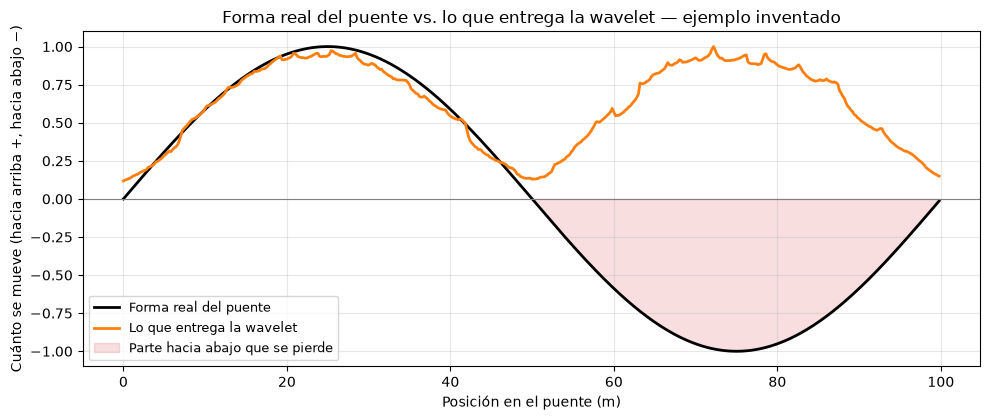

In [5]:
# Bridge shape from the wavelet: mean strength of the 1.3 Hz note at each position
band = np.abs(freqs_ssq - f_mode) <= 0.3     # only the bridge note (1.3 +/- 0.3 Hz)
shape_wavelet = np.abs(Tx[band]).mean(axis=0)
shape_wavelet /= shape_wavelet.max()         # normalized: 1 = largest movement

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos, shape_true, "k-", lw=2, label="Forma real del puente")
ax.plot(pos, shape_wavelet, color="C1", lw=2, label="Lo que entrega la wavelet")
ax.fill_between(pos, shape_true, 0, where=shape_true < 0, color="C3", alpha=0.15,
                label="Parte hacia abajo que se pierde")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Posición en el puente (m)")
ax.set_ylabel("Cuánto se mueve (hacia arriba +, hacia abajo −)")
ax.set_title("Forma real del puente vs. lo que entrega la wavelet — ejemplo inventado")
ax.legend(loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

**Figura 4.** Forma real del puente comparada con la que entrega la wavelet (ilustrativo, datos sintéticos): la mitad que en realidad baja (de 50 a 100 m) aparece hacia arriba, porque la wavelet solo dice cuánto se mueve cada punto, no hacia qué lado.

**Ventajas**

- Sirve para vibraciones cortas y que cambian.
- Dice a la vez qué nota suena y dónde.

**Desventajas**

- Hay que saber de antemano qué nota buscar.
- Dice qué tan fuerte se mueve cada punto, pero no hacia qué lado; el dibujo sale sin la parte "hacia abajo".
- Analogía: es como saber a qué distancia está alguien de la puerta, pero no si está a la izquierda o a la derecha.
- No separa la vibración del puente de la del carro.

**Artículos:** Dabbaghchian et al. (2025).

**Entradas y salidas**

- **Entrada:** la vibración que midió el teléfono, la ubicación del carro (GPS) y la nota del puente que se quiere buscar.
- **Salida:** un mapa de colores que dice qué notas suenan y en qué punto del puente.
- **Qué se obtiene o interpreta:** en qué partes del puente vibra más esa nota y, juntando muchos viajes, la forma en que se deforma el puente, sin saber hacia qué lado.

[↑ Volver al índice](#indice)